# P3: locked local-test evaluation

All 18 checkpoints and prediction rules were fixed before opening test scores. Primary configurations are width 256, selected by three-seed mean validation accuracy; the designated single model uses seed 42 for every dataset. The evaluation performs no fitting or post-test model selection. The 90% reference is a coursework target, not a claim about hidden-set accuracy.

This notebook only reads saved evaluation artifacts. Source code, data, checkpoint and lock hashes were checked before evaluation; row-aligned predictions were independently verified afterward. See `member_c/configs/p3_lock.json` and `member_c/results/p3_test/verification.json`.

**Display:** Run all cells to plot directly below the code with `plt.show()`. No PDF or image files are exported. Matplotlib renders mathematical labels without external LaTeX.


In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'common.py').is_file())
assert Path(sys.prefix).resolve()==(root/'.venv').resolve()
report=json.loads((root/'member_c/results/p3_test/summary.json').read_text())
groups=report['groups']
header='| Dataset | Width | Validation mean | Test mean ± sample SD | Test rows |\n|---|---|---:|---:|---:|'
lines=[f"| {g['dataset']} | {g['width']} × {g['width']} | {100*g['mean_validation_accuracy']:.2f}% | {100*g['mean_test_accuracy']:.2f} ± {100*g['sample_std_test_accuracy']:.2f}% | {g['test_size']} |" for g in groups]
display(Markdown(header+'\n'+'\n'.join(lines)))


| Dataset | Width | Validation mean | Test mean ± sample SD | Test rows |
|---|---|---:|---:|---:|
| 20 | 128 × 128 | 90.36% | 88.92 ± 0.14% | 1200 |
| 20 | 256 × 256 | 90.57% | 89.42 ± 0.80% | 1200 |
| 30 | 128 × 128 | 89.63% | 90.75 ± 1.78% | 2000 |
| 30 | 256 × 256 | 91.03% | 91.87 ± 0.63% | 2000 |
| 40 | 128 × 128 | 93.08% | 92.69 ± 0.95% | 3200 |
| 40 | 256 × 256 | 93.49% | 93.64 ± 0.69% | 3200 |

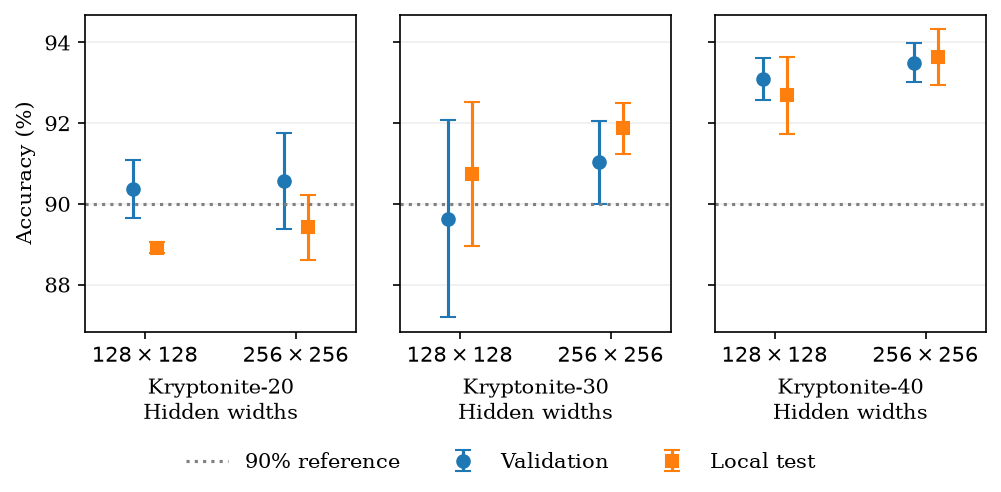

In [2]:
# Plot directly in the notebook; no file export or external LaTeX required.
plt.rcParams.update({
    'text.usetex': False, 'font.family': 'serif', 'font.serif': ['DejaVu Serif'],
    'font.size': 10.1, 'axes.labelsize': 10.1, 'xtick.labelsize': 10.1,
    'ytick.labelsize': 10.1, 'legend.fontsize': 10.1, 'figure.titlesize': 10.1,
    'axes.unicode_minus': True, 'figure.dpi': 150,
})
fig,axes=plt.subplots(1,3,figsize=(6.75,3.25),sharey=True,constrained_layout=False)
for ax,dataset in zip(axes,['20','30','40']):
    for i,width in enumerate([128,256]):
        g=next(g for g in groups if g['dataset']==dataset and g['width']==width)
        selected=[m for m in report['models'] if m['dataset']==dataset and m['width']==width]
        val_std=np.std([m['validation_accuracy'] for m in selected],ddof=1)
        ax.errorbar(i-0.08,100*g['mean_validation_accuracy'],yerr=100*val_std,fmt='o',color='tab:blue',capsize=4,label='Validation' if i==0 else None)
        ax.errorbar(i+0.08,100*g['mean_test_accuracy'],yerr=100*g['sample_std_test_accuracy'],fmt='s',color='tab:orange',capsize=4,label='Local test' if i==0 else None)
    ax.axhline(90,color='0.5',linestyle=':',label=r'90% reference')
    ax.set_xticks([0,1],[r'$128\times128$',r'$256\times256$'])
    ax.set(xlabel=f'Kryptonite-{dataset}'+ '\nHidden widths',xlim=(-0.4,1.4))
    ax.grid(axis='y',alpha=0.2)
axes[0].set_ylabel(r'Accuracy (%)')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, frameon=False)
fig.subplots_adjust(left=0.10, right=0.99, top=0.97, bottom=0.32, wspace=0.16)
plt.show()


**Figure.** Mean accuracy ± one sample standard deviation over the three predeclared training seeds, with the same split used for every model. These error bars describe training variability, not confidence intervals. Validation was used for checkpoint/configuration selection; local test scores were opened only after locking all models. No test ranking changes the declared primary configuration or seed.


In [3]:
header='| Dataset | Fixed single model | Correct / n | Test accuracy | Wilson 95% interval |\n|---|---|---:|---:|---|'
lines=[f"| {m['dataset']} | 256 × 256, seed 42 | {m['test_correct']} / {m['test_size']} | {m['test_metrics']['accuracy']:.2%} | {m['accuracy_wilson95'][0]:.2%}–{m['accuracy_wilson95'][1]:.2%} |" for m in report['designated_single_models']]
display(Markdown(header+'\n'+'\n'.join(lines)))


| Dataset | Fixed single model | Correct / n | Test accuracy | Wilson 95% interval |
|---|---|---:|---:|---|
| 20 | 256 × 256, seed 42 | 1077 / 1200 | 89.75% | 87.91%–91.34% |
| 30 | 256 × 256, seed 42 | 1843 / 2000 | 92.15% | 90.89%–93.25% |
| 40 | 256 × 256, seed 42 | 2984 / 3200 | 93.25% | 92.33%–94.07% |

The Wilson intervals describe test-sample uncertainty for each fixed single model. They do not combine the three seeds or include training variability. Kryptonite-20 is below the 90% reference by point estimate, although the fixed-model interval spans 90%. This is not evidence that its hidden accuracy meets the target. Models and policies remain fixed; future full-data refitting, if assigned, is a separate unscored artifact.
